<a href="https://colab.research.google.com/github/ANANDA-SWAROOP/sem-7-assignments/blob/main/Assignment1_Multilingual_Transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1 — Comparative Evaluation of Multilingual Transformers for Indian-Language Sentiment Analysis

**Task:** binary sentiment classification (positive / negative) of product reviews  
**Dataset:** `ai4bharat/IndicSentiment` — *human-translated* parallel reviews (same English source review in every language), the human-annotated benchmark used in the reference paper (IndiSentiment140, NAACL 2024).  
**Languages:** English + 12 Indian languages — Assamese, Bengali, Gujarati, Hindi, Kannada, Malayalam, Marathi, Odia, Punjabi, Tamil, Telugu, Urdu  
**Models (same recipe for all):** mBERT (`bert-base-multilingual-cased`), XLM-RoBERTa-base (`xlm-roberta-base`), IndicBERT v2 (`ai4bharat/IndicBERTv2-MLM-only`)

## What makes this study different from a plain "train 3 models, report accuracy"
| Design choice | Why it matters |
|---|---|
| **Parallel data, review-level split** | The same review exists in 13 languages. Splitting by *review id* (not by row) prevents the Hindi translation of a training review leaking into the Tamil test set. |
| **Two experimental regimes** | (A) *Joint multilingual fine-tuning* on all languages; (B) *Zero-shot cross-lingual transfer* — train on English only, test on the 12 Indian languages. B isolates the cross-lingual quality of each model's representation. |
| **Languages deliberately chosen to break the models** | Assamese and Odia are **not** in mBERT's pretraining data but are in XLM-R and IndicBERT v2 → a natural "seen vs unseen language" experiment. |
| **Tokenizer diagnostics** | Fertility (subwords per word), UNK rate and truncation rate per tokenizer × language, then correlated with accuracy. |
| **Paired bootstrap over reviews** | Because test reviews are parallel, we resample *reviews* (not rows) to get honest confidence intervals on model differences. |
| **Parallel-review error decomposition** | Separates "this review is intrinsically hard/ambiguous" (all models fail in all languages) from "this model fails in this language" . |
| **Code-mixing / residual-English analysis** | Re-tests the reference paper's finding on Latin-script noise inside Indic text, for fine-tuned Transformers. |

## Mapping to the assignment requirements
| Req. | Where |
|---|---|
| 1 Task & dataset | Sections 3–4 |
| 2 Three models | Section 2 (`MODELS`) |
| 3 Comparable setup | Section 2 (shared hyper-parameters, splits, seeds) and Section 6 |
| 4 Metrics | `compute_metrics` — Accuracy, Precision, Recall (macro & weighted), Macro-F1, Weighted-F1 |
| 5 Comparative table | Section 7.1 |
| 6 Language-wise comparison | Section 7.2 |
| 7 Analysis by pretraining / languages / tokenization / transfer / architecture / dataset / language traits | Sections 5, 7.3–7.5 and the report guide at the end |
| 8 Error analysis | Section 8 |
| 9 Why a model wins or loses | Section 9 (auto-generated evidence) + report guide |
| 10 Conclusions backed by results | Section 9 |

## 0. Colab setup (do this first)
1. Open <https://colab.research.google.com> → **File → Upload notebook** → select this `.ipynb`.
2. **Runtime → Change runtime type → T4 GPU** (free tier is enough) → Save.
3. Run cells top to bottom. The first cell mounts Google Drive so predictions are saved after every run — if Colab disconnects, just re-run from the top: finished runs are skipped automatically.
4. Expected runtime on a T4 with the default settings (3 seeds × 2 regimes × 3 models): roughly **1–1.5 hours**. For a smoke test set `QUICK_RUN = True` in Section 2 (≈10 min).
5. No Hugging Face token is needed (all models and the dataset are public).

## 1. Environment

In [ ]:
!pip -q install sentencepiece protobuf huggingface_hub
import torch, transformers, sys
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE -> switch runtime to GPU!")

# Persist results to Google Drive (optional but recommended)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive not mounted (running outside Colab?):", e)

Python 3.13.15 | torch 2.11.0+cu130 | transformers 5.18.0
GPU: Tesla T4
Mounted at /content/drive


## 2. Configuration (identical for every model → comparable setup)

In [ ]:
import os, re, json, time, random, copy, warnings
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix)
from sklearn.model_selection import train_test_split
from scipy.stats import spearmanr
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
warnings.filterwarnings("ignore")

# ------------------------- experiment switches -------------------------
QUICK_RUN = False            # True = smoke test (1 seed, 4 languages, few epochs)

MODELS = {                   # short name -> Hugging Face id
    "mBERT":       "bert-base-multilingual-cased",
    "XLM-R":       "xlm-roberta-base",
    "IndicBERTv2": "ai4bharat/IndicBERTv2-MLM-only",
}
LANGS = ["as", "bn", "gu", "hi", "kn", "ml", "mr", "or", "pa", "ta", "te", "ur"]   # + "en" added automatically
SEEDS = [42, 43, 44]
SETUPS = ["joint", "zeroshot"]          # joint = train on all languages | zeroshot = train on English only
EPOCHS = {"joint": 3, "zeroshot": 8}    # zero-shot has only ~700 training reviews, so more passes
MAX_LEN, BATCH, LR, WEIGHT_DECAY, WARMUP = 128, 32, 3e-5, 0.01, 0.1
SPLIT_SEED = 2026                       # data split is fixed; only training seeds vary
if QUICK_RUN:
    LANGS, SEEDS, EPOCHS = ["hi", "ta", "te", "as"], [42], {"joint": 1, "zeroshot": 3}

LANG_INFO = {   # language -> (name, script, family)
    "en": ("English", "Latin", "Germanic"),   "as": ("Assamese", "Bengali-Assamese", "Indo-Aryan"),
    "bn": ("Bengali", "Bengali-Assamese", "Indo-Aryan"), "gu": ("Gujarati", "Gujarati", "Indo-Aryan"),
    "hi": ("Hindi", "Devanagari", "Indo-Aryan"),  "kn": ("Kannada", "Kannada", "Dravidian"),
    "ml": ("Malayalam", "Malayalam", "Dravidian"), "mr": ("Marathi", "Devanagari", "Indo-Aryan"),
    "or": ("Odia", "Odia", "Indo-Aryan"),         "pa": ("Punjabi", "Gurmukhi", "Indo-Aryan"),
    "ta": ("Tamil", "Tamil", "Dravidian"),        "te": ("Telugu", "Telugu", "Dravidian"),
    "ur": ("Urdu", "Perso-Arabic", "Indo-Aryan"),
}
# Is the language in the model's pretraining data? (from the model papers/cards - verify before submitting)
COVERAGE = {
    "mBERT":       {"en", "bn", "gu", "hi", "kn", "ml", "mr", "pa", "ta", "te", "ur"},   # NOT as, or
    "XLM-R":       set(LANG_INFO),
    "IndicBERTv2": set(LANG_INFO),
}
METRICS = ["accuracy", "precision_macro", "recall_macro", "f1_macro",
           "precision_weighted", "recall_weighted", "f1_weighted"]

BASE = "/content/drive/MyDrive" if os.path.exists("/content/drive/MyDrive") else "/content"
OUT_DIR = f"{BASE}/nlp_assignment1" + ("_quick" if QUICK_RUN else "")
os.makedirs(OUT_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def compute_metrics(y, p):
    return dict(
        accuracy=accuracy_score(y, p),
        precision_macro=precision_score(y, p, average="macro", zero_division=0),
        recall_macro=recall_score(y, p, average="macro", zero_division=0),
        f1_macro=f1_score(y, p, average="macro", zero_division=0),
        precision_weighted=precision_score(y, p, average="weighted", zero_division=0),
        recall_weighted=recall_score(y, p, average="weighted", zero_division=0),
        f1_weighted=f1_score(y, p, average="weighted", zero_division=0))
print("Output dir:", OUT_DIR, "| device:", DEVICE)

Output dir: /content/drive/MyDrive/nlp_assignment1 | device: cuda


## 3. Dataset: download and align the parallel reviews
`IndicSentiment` ships one JSON file per language (`data/test/<lang>.json`). Each record has the English review, its **human translation**, and a polarity label. We align languages through the English review text, keep only reviews present in every language, and drop non-binary labels.

In [ ]:
from huggingface_hub import hf_hub_download, HfApi
REPO = "ai4bharat/IndicSentiment"
LABEL_MAP = {"positive": 1, "negative": 0}

def hf_file(lang, split="test"):
    try:
        return hf_hub_download(REPO, f"data/{split}/{lang}.json", repo_type="dataset")
    except Exception as e:
        files = [f for f in HfApi().list_repo_files(REPO, repo_type="dataset") if f.startswith("data/")]
        raise RuntimeError(f"Could not fetch data/{split}/{lang}.json ({e}).\nFiles in repo: {files}")

def read_records(path):
    raw = open(path, encoding="utf-8").read().strip()
    try:
        obj = json.loads(raw)
        if isinstance(obj, dict):
            for k in ("data", "rows", "records"):
                if isinstance(obj.get(k), list):
                    return obj[k]
            return list(obj.values()) if all(isinstance(v, dict) for v in obj.values()) else [obj]
        return obj
    except json.JSONDecodeError:                      # JSON-lines
        return [json.loads(l) for l in raw.splitlines() if l.strip()]

norm = lambda k: re.sub(r"[^A-Z]", "", str(k).upper())   # 'INDIC REVIEW' -> 'INDICREVIEW'

frames, dropped = {}, {}
for lang in LANGS:
    recs = read_records(hf_file(lang))
    rows, bad = [], 0
    for r in recs:
        nk = {norm(k): v for k, v in r.items()}
        lab = LABEL_MAP.get(str(nk.get("LABEL")).strip().lower())
        ind, eng = nk.get("INDICREVIEW"), nk.get("ENGLISHREVIEW")
        if lab is None or not ind or not eng:
            bad += 1; continue
        rows.append((str(eng).strip(), str(ind).strip(), lab))
    if not rows:
        raise RuntimeError(f"No usable rows for '{lang}'. Keys of first record: {list(recs[0].keys())}")
    frames[lang] = pd.DataFrame(rows, columns=["english", "text", "label"]).drop_duplicates("english").set_index("english")
    dropped[lang] = bad
print("Records per language:", {l: len(f) for l, f in frames.items()})
print("Dropped (neutral/missing):", dropped)

common = sorted(set.intersection(*[set(f.index) for f in frames.values()]))
ref = frames[LANGS[0]].loc[common, "label"]
for l in LANGS[1:]:                                       # labels must agree across translations
    mism = (frames[l].loc[common, "label"] != ref).sum()
    if mism: print(f"WARNING {l}: {mism} label mismatches vs {LANGS[0]} (kept reference label)")
print(f"Reviews present in all {len(LANGS)} languages: {len(common)}")

as.json:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

bn.json:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

gu.json:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

hi.json:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

kn.json:   0%|          | 0.00/1.25M [00:00<?, ?B/s]

...

pa.json:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

ta.json:   0%|          | 0.00/1.31M [00:00<?, ?B/s]

te.json:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

ur.json:   0%|          | 0.00/1.13M [00:00<?, ?B/s]

Records per language: {'as': 996, 'bn': 996, 'gu': 996, 'hi': 996, 'kn': 996, 'ml': 996, 'mr': 996, 'or': 996, 'pa': 996, 'ta': 996, 'te': 996, 'ur': 996}
Dropped (neutral/missing): {'as': 2, 'bn': 2, 'gu': 2, 'hi': 2, 'kn': 2, 'ml': 2, 'mr': 2, 'or': 2, 'pa': 2, 'ta': 2, 'te': 2, 'ur': 2}
Reviews present in all 12 languages: 996


In [ ]:
# ---- review-level stratified split: 70 / 10 / 20 (train / dev / test) ----
rid_of = {eng: i for i, eng in enumerate(common)}
ids = np.arange(len(common)); labels = ref.values
tr_ids, rest_ids = train_test_split(ids, test_size=0.30, stratify=labels, random_state=SPLIT_SEED)
dv_ids, te_ids = train_test_split(rest_ids, test_size=2/3, stratify=labels[rest_ids], random_state=SPLIT_SEED)
split_of = {**{i: "train" for i in tr_ids}, **{i: "dev" for i in dv_ids}, **{i: "test" for i in te_ids}}

rows = []
for eng in common:
    i = rid_of[eng]
    rows.append((i, "en", eng, int(ref.loc[eng]), eng, split_of[i]))
    for l in LANGS:
        rows.append((i, l, frames[l].loc[eng, "text"], int(ref.loc[eng]), eng, split_of[i]))
df = pd.DataFrame(rows, columns=["review_id", "lang", "text", "label", "english", "split"])
ALL_LANGS = ["en"] + LANGS

print(df.groupby("split").review_id.nunique().rename("reviews per split").to_frame().T)
print("Label balance (positive share) per split:")
print(df[df.lang == "en"].groupby("split").label.mean().round(3).to_frame("positive_share").T)
print("Same review never crosses splits ->", df.groupby("review_id").split.nunique().max() == 1)

split              dev  test  train
reviews per split   99   200    697
Label balance (positive share) per split:
split             dev  test  train
positive_share  0.505  0.51  0.506
Same review never crosses splits -> True


## 4. Exploratory analysis of the dataset (supports *dataset characteristics* analysis)

In [ ]:
latin_word = re.compile(r"[A-Za-z]")
def latin_share(t):
    w = t.split()
    return sum(bool(latin_word.search(x)) for x in w) / max(1, len(w))
df["n_words"] = df.text.str.split().str.len()
df["latin_share"] = np.where(df.lang == "en", np.nan, df.text.map(latin_share))   # residual English in Indic text (paper's "noise")

eda = (df.groupby("lang").agg(reviews=("review_id", "nunique"),
                              avg_words=("n_words", "mean"),
                              max_words=("n_words", "max"),
                              pct_reviews_with_latin=("latin_share", lambda s: 100 * (s > 0).mean()),
                              avg_latin_share_pct=("latin_share", lambda s: 100 * s.mean()))
         .loc[ALL_LANGS].round(2))
eda.insert(0, "script", [LANG_INFO[l][1] for l in eda.index]); eda.insert(1, "family", [LANG_INFO[l][2] for l in eda.index])
display(eda)
print("Positive share overall: %.3f  -> the classes are %s" % (df[df.lang=='en'].label.mean(),
      "balanced enough that accuracy ~ weighted-F1, but we still headline Macro-F1" ))
eda.to_csv(f"{OUT_DIR}/dataset_stats.csv")

,script,family,reviews,avg_words,max_words,pct_reviews_with_latin,avg_latin_share_pct
lang,,,,,,,
en,Latin,Germanic,996,23.24,97,0.00,NaN
as,Bengali-Assamese,Indo-Aryan,996,20.33,80,10.84,0.73
bn,Bengali-Assamese,Indo-Aryan,996,20.74,88,0.20,0.01
gu,Gujarati,Indo-Aryan,996,23.07,93,6.02,0.43
hi,Devanagari,Indo-Aryan,996,26.86,100,2.91,0.14
kn,Kannada,Dravidian,996,17.09,67,0.80,0.05
ml,Malayalam,Dravidian,996,15.94,62,6.93,0.58
mr,Devanagari,Indo-Aryan,996,20.11,74,5.32,0.42
or,Odia,Indo-Aryan,996,22.18,88,18.27,1.03


Positive share overall: 0.507  -> the classes are balanced enough that accuracy ~ weighted-F1, but we still headline Macro-F1


In [ ]:
# ---- Tokenizers + tokenization diagnostics (fertility / UNK / truncation) ----
TOK = {}
for k, name in MODELS.items():
    try:
        TOK[k] = AutoTokenizer.from_pretrained(name)
    except Exception as e:
        print(f"[{k}] fast tokenizer failed ({e}); retrying with use_fast=False")
        TOK[k] = AutoTokenizer.from_pretrained(name, use_fast=False)

def tok_stats(tok, texts):
    texts = list(texts)
    ids = tok(texts, add_special_tokens=False)["input_ids"]
    n_tok = np.array([len(x) for x in ids]); n_w = np.array([max(1, len(t.split())) for t in texts])
    unk = np.nan if tok.unk_token_id is None else np.mean([(np.array(x) == tok.unk_token_id).mean() if len(x) else 0 for x in ids])
    return dict(fertility=n_tok.sum() / n_w.sum(), unk_rate=100 * unk, truncated_pct=100 * np.mean(n_tok + 2 > MAX_LEN), avg_tokens=n_tok.mean())

fert_rows = []
for k, tok in TOK.items():
    for l in ALL_LANGS:
        fert_rows.append(dict(model=k, lang=l, **tok_stats(tok, df[df.lang == l].text)))
fert = pd.DataFrame(fert_rows)
print("Vocabulary sizes:", {k: len(t) for k, t in TOK.items()})
fp = fert.pivot(index="lang", columns="model", values="fertility").loc[ALL_LANGS][list(MODELS)]
display(fp.round(2).style.background_gradient(cmap="Reds", axis=None).set_caption("Tokenizer fertility = subwords per whitespace word (lower is better)"))
display(fert.pivot(index="lang", columns="model", values="unk_rate").loc[ALL_LANGS][list(MODELS)].round(2).rename_axis(columns="UNK rate (%)"))
display(fert.pivot(index="lang", columns="model", values="truncated_pct").loc[ALL_LANGS][list(MODELS)].round(1).rename_axis(columns=f"% reviews truncated at {MAX_LEN} tokens"))
fert.to_csv(f"{OUT_DIR}/tokenizer_stats.csv", index=False)

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Vocabulary sizes: {'mBERT': 119547, 'XLM-R': 250002, 'IndicBERTv2': 250000}


model,mBERT,XLM-R,IndicBERTv2
lang,,,
en,1.380000,1.370000,1.240000
as,3.960000,2.900000,1.580000
bn,2.690000,2.070000,1.410000
gu,3.100000,1.920000,1.430000
hi,2.090000,1.560000,1.280000
kn,3.860000,2.470000,1.780000
ml,4.750000,2.700000,1.960000
mr,3.010000,1.950000,1.510000
or,1.070000,2.080000,1.440000


UNK rate (%),mBERT,XLM-R,IndicBERTv2
lang,,,
en,0.06,0.00,0.00
as,0.85,0.00,0.00
bn,3.52,0.00,0.00
gu,0.00,0.00,0.00
hi,0.66,0.00,0.00
kn,0.02,0.00,0.00
ml,0.01,0.01,0.01
mr,0.27,0.00,0.00
or,86.42,0.00,0.00


% reviews truncated at 128 tokens,mBERT,XLM-R,IndicBERTv2
lang,,,
en,0.1,0.1,0.1
as,12.9,3.6,0.1
bn,3.3,1.0,0.1
gu,7.4,1.3,0.1
hi,2.4,0.8,0.1
kn,5.6,0.8,0.1
ml,9.9,1.2,0.1
mr,3.8,0.5,0.1
or,0.0,1.3,0.1


## 5. Training and evaluation code (one function, used identically for all models)
* AdamW, linear warm-up/decay, fp16 autocast, gradient clipping 1.0, dynamic padding, `max_len=128`.
* The **epoch with the best dev Macro-F1** is restored before testing (same rule for every model).
* Test predictions for every review × language are stored → every later table, test and error analysis is computed from these files.

In [ ]:
class TextDS(Dataset):
    def __init__(self, d): self.t, self.y = d.text.tolist(), d.label.tolist()
    def __len__(self): return len(self.t)
    def __getitem__(self, i): return self.t[i], self.y[i]

def make_loader(d, tok, shuffle, seed=0, bs=BATCH):
    def collate(b):
        texts, ys = zip(*b)
        enc = tok(list(texts), truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
        enc["labels"] = torch.tensor(ys)
        return enc
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(TextDS(d), batch_size=bs, shuffle=shuffle, collate_fn=collate, generator=g)

@torch.no_grad()
def predict_probs(model, loader):
    model.eval(); out = []
    for enc in loader:
        enc = {k: v.to(DEVICE) for k, v in enc.items()}; enc.pop("labels")
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**enc).logits
        out.append(F.softmax(logits.float(), -1).cpu().numpy())
    return np.concatenate(out)

def train_and_predict(model_key, setup, seed):
    set_seed(seed)
    tok = TOK[model_key]
    if setup == "joint":
        tr, dv = df[df.split == "train"], df[df.split == "dev"]
    else:                                                  # zero-shot: English only
        tr, dv = df[(df.split == "train") & (df.lang == "en")], df[(df.split == "dev") & (df.lang == "en")]
    tr, dv = tr.reset_index(drop=True), dv.reset_index(drop=True)
    te = df[df.split == "test"].reset_index(drop=True)

    model = AutoModelForSequenceClassification.from_pretrained(MODELS[model_key], num_labels=2).to(DEVICE)
    nd = ("bias", "LayerNorm", "layer_norm")
    groups = [{"params": [p for n, p in model.named_parameters() if not any(x in n for x in nd)], "weight_decay": WEIGHT_DECAY},
              {"params": [p for n, p in model.named_parameters() if any(x in n for x in nd)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(groups, lr=LR)
    tl = make_loader(tr, tok, True, seed); dl = make_loader(dv, tok, False); tel = make_loader(te, tok, False)
    total = len(tl) * EPOCHS[setup]
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP * total), total)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    best_f1, best_state, log, t0 = -1, None, [], time.time()
    for ep in range(EPOCHS[setup]):
        model.train(); run = 0.0
        for enc in tl:
            enc = {k: v.to(DEVICE) for k, v in enc.items()}; y = enc.pop("labels")
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(**enc).logits
            loss = F.cross_entropy(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); run += loss.item()
        dp = predict_probs(model, dl).argmax(1)
        f1 = f1_score(dv.label, dp, average="macro")
        log.append(dict(epoch=ep + 1, train_loss=run / len(tl), dev_macro_f1=f1))
        print(f"   epoch {ep+1}/{EPOCHS[setup]}  loss {run/len(tl):.4f}  dev macro-F1 {f1:.4f}")
        if f1 > best_f1:
            best_f1, best_state = f1, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    probs = predict_probs(model, tel)
    out = pd.DataFrame(dict(model=model_key, setup=setup, seed=seed, review_id=te.review_id, lang=te.lang,
                            y_true=te.label, y_pred=probs.argmax(1), p_pos=probs[:, 1]))
    info = dict(model=model_key, setup=setup, seed=seed, best_dev_f1=best_f1, seconds=time.time() - t0,
                n_train=len(tr), n_params_M=sum(p.numel() for p in model.parameters()) / 1e6, log=log)
    del model, opt, best_state; torch.cuda.empty_cache()
    return out, info

## 6. Run all experiments (resumable)

In [ ]:
for seed in SEEDS:                       # seed is the outer loop so a partial run still gives a complete seed
    for setup in SETUPS:
        for mk in MODELS:
            f = Path(OUT_DIR) / f"preds_{mk}_{setup}_{seed}.csv"
            if f.exists():
                print(f"skip (done): {f.name}"); continue
            print(f"\n=== model={mk} | setup={setup} | seed={seed} ===")
            out, info = train_and_predict(mk, setup, seed)
            out.to_csv(f, index=False)
            json.dump(info, open(Path(OUT_DIR) / f"log_{mk}_{setup}_{seed}.json", "w"), indent=1)
            print(f"   done in {info['seconds']/60:.1f} min | params {info['n_params_M']:.0f}M")
print("\nAll runs finished.")


=== model=mBERT | setup=joint | seed=42 ===


model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


   epoch 1/8  loss 0.6902  dev macro-F1 0.9085
   epoch 2/8  loss 0.3620  dev macro-F1 0.9596
   epoch 3/8  loss 0.1751  dev macro-F1 0.9697
   epoch 4/8  loss 0.1019  dev macro-F1 0.9697
   epoch 5/8  loss 0.0894  dev macro-F1 0.9697
   epoch 6/8  loss 0.0371  dev macro-F1 0.9798
   epoch 7/8  loss 0.0280  dev macro-F1 0.9697
   epoch 8/8  loss 0.0388  dev macro-F1 0.9697
   done in 0.8 min | params 278M

=== model=IndicBERTv2 | setup=zeroshot | seed=44 ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai4bharat/IndicBERTv2-MLM-only
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

   epoch 1/8  loss 0.6864  dev macro-F1 0.8283
   epoch 2/8  loss 0.3949  dev macro-F1 0.9394
   epoch 3/8  loss 0.1263  dev macro-F1 0.9596
   epoch 4/8  loss 0.0527  dev macro-F1 0.9899
   epoch 5/8  loss 0.0217  dev macro-F1 0.9596
   epoch 6/8  loss 0.0080  dev macro-F1 0.9798
   epoch 7/8  loss 0.0031  dev macro-F1 0.9697
   epoch 8/8  loss 0.0021  dev macro-F1 0.9697
   done in 0.8 min | params 278M

All runs finished.


## 7. Results
### 7.1 Comparative results table (all three models, same data / same recipe)
Numbers are **mean ± std over training seeds**, computed on the held-out test reviews. The row is the *macro-average over the 12 Indian languages* (each language weighted equally); English is reported separately.

In [ ]:
pred_files = sorted(Path(OUT_DIR).glob("preds_*.csv"))
preds = pd.concat([pd.read_csv(f) for f in pred_files], ignore_index=True)
print(f"Loaded {len(pred_files)} prediction files | seeds: {sorted(preds.seed.unique())}")

rows = []
for (m, s, seed, l), g in preds.groupby(["model", "setup", "seed", "lang"]):
    rows.append(dict(model=m, setup=s, seed=seed, lang=l, n=len(g), **compute_metrics(g.y_true, g.y_pred)))
M = pd.DataFrame(rows)
M.to_csv(f"{OUT_DIR}/metrics_per_seed_lang.csv", index=False)

def ms(x):
    sd = x.std(ddof=1) if len(x) > 1 else 0.0
    return f"{100*x.mean():.2f} ± {100*sd:.2f}"

def overall_table(frame, title):
    per_seed = frame.groupby(["setup", "model", "seed"])[METRICS].mean().reset_index()
    t = per_seed.groupby(["setup", "model"])[METRICS].agg(ms)
    t.columns = ["Accuracy", "Precision (macro)", "Recall (macro)", "Macro-F1", "Precision (wtd)", "Recall (wtd)", "Weighted-F1"]
    print(title); display(t)
    return per_seed

ps_indic = overall_table(M[M.lang != "en"], "▶ Macro-average over the 12 Indian languages (%)")
_ = overall_table(M[M.lang == "en"], "▶ English test set (%)")
ps_indic.groupby(["setup", "model"])[METRICS].mean().round(4).to_csv(f"{OUT_DIR}/table_overall_indic.csv")

nparams = {json.load(open(f))["model"]: json.load(open(f))["n_params_M"] for f in Path(OUT_DIR).glob("log_*.json")}
print("Parameters (M):", {k: round(v) for k, v in nparams.items()})

Loaded 18 prediction files | seeds: [np.int64(42), np.int64(43), np.int64(44)]
▶ Macro-average over the 12 Indian languages (%)


Accuracy Precision (macro) Recall (macro)  \
setup    model                                                        
joint    IndicBERTv2  96.21 ± 0.07      96.25 ± 0.07   96.21 ± 0.09   
         XLM-R        94.42 ± 0.18      94.47 ± 0.17   94.43 ± 0.18   
         mBERT        83.15 ± 0.28      83.23 ± 0.32   83.17 ± 0.31   
zeroshot IndicBERTv2  95.68 ± 1.38      95.83 ± 1.22   95.70 ± 1.34   
         XLM-R        91.57 ± 1.78      92.23 ± 1.24   91.58 ± 1.68   
         mBERT        73.28 ± 1.56      73.22 ± 2.23   73.44 ± 1.48   

                          Macro-F1 Precision (wtd)  Recall (wtd)   Weighted-F1  
setup    model                                                                  
joint    IndicBERTv2  96.21 ± 0.07    96.26 ± 0.08  96.21 ± 0.07  96.21 ± 0.07  
         XLM-R        94.41 ± 0.18    94.48 ± 0.17  94.42 ± 0.18  94.41 ± 0.18  
         mBERT        83.09 ± 0.24    83.24 ± 0.34  83.15 ± 0.28  83.09 ± 0.24  
zeroshot IndicBERTv2  95.68 ± 1.39    95.85 ± 1.18  95.68 ± 1.38  95.67 ± 1.39  
         XLM-R        91.50 ± 1.85    92.24 ± 1.16  91.57 ± 1.78  91.50 ± 1.87  
         mBERT        72.06 ± 2.45    73.27 ± 2.25  73.28 ± 1.56  72.01 ± 2.49

▶ English test set (%)


Accuracy Precision (macro) Recall (macro)  \
setup    model                                                        
joint    IndicBERTv2  96.17 ± 0.76      96.22 ± 0.70   96.16 ± 0.80   
         XLM-R        98.00 ± 0.50      98.00 ± 0.49   98.01 ± 0.49   
         mBERT        86.50 ± 1.80      86.64 ± 1.71   86.56 ± 1.78   
zeroshot IndicBERTv2  94.83 ± 1.26      95.02 ± 1.03   94.89 ± 1.21   
         XLM-R        97.17 ± 0.29      97.22 ± 0.25   97.20 ± 0.25   
         mBERT        86.50 ± 1.32      86.66 ± 1.21   86.56 ± 1.30   

                          Macro-F1 Precision (wtd)  Recall (wtd)   Weighted-F1  
setup    model                                                                  
joint    IndicBERTv2  96.16 ± 0.77    96.22 ± 0.73  96.17 ± 0.76  96.17 ± 0.77  
         XLM-R        98.00 ± 0.50    98.02 ± 0.48  98.00 ± 0.50  98.00 ± 0.50  
         mBERT        86.50 ± 1.81    86.69 ± 1.70  86.50 ± 1.80  86.49 ± 1.81  
zeroshot IndicBERTv2  94.83 ± 1.26    95.08 ± 0.99  94.83 ± 1.26  94.83 ± 1.27  
         XLM-R        97.17 ± 0.29    97.25 ± 0.22  97.17 ± 0.29  97.17 ± 0.29  
         mBERT        86.50 ± 1.33    86.71 ± 1.20  86.50 ± 1.32  86.49 ± 1.33

Parameters (M): {'mBERT': 178, 'XLM-R': 278, 'IndicBERTv2': 278}


### 7.2 Language-wise comparison

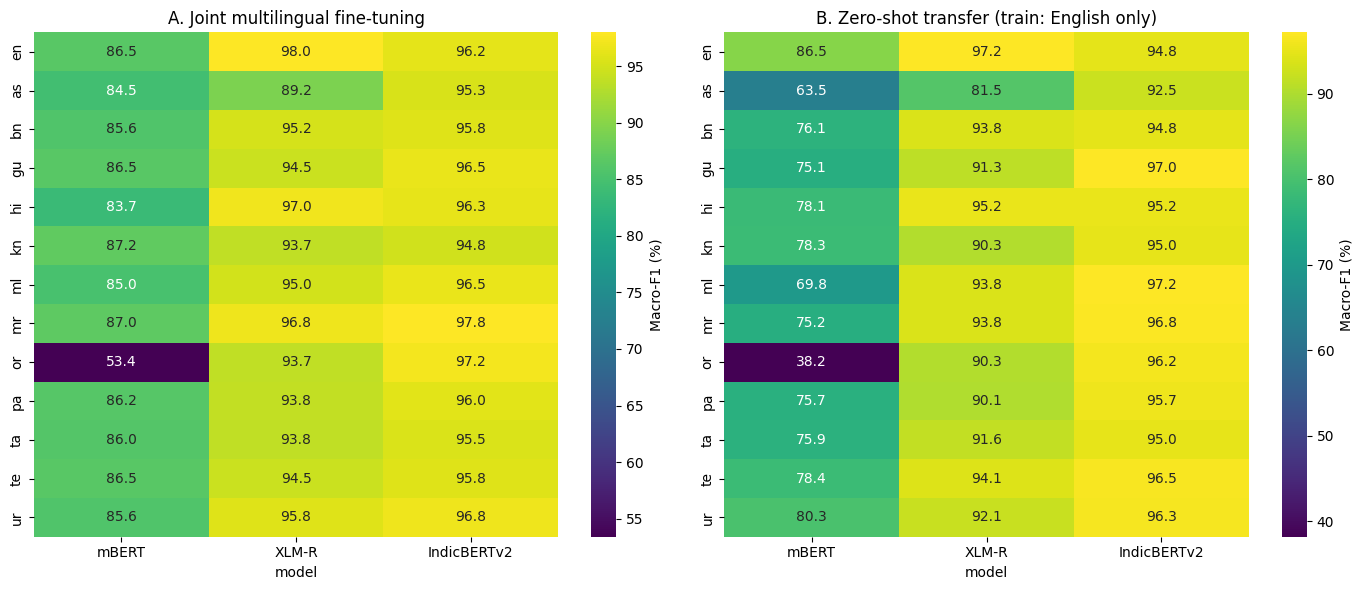


▶ f1_macro per language | setup = joint


model,mBERT,XLM-R,IndicBERTv2
en (English),86.50 ± 1.81,98.00 ± 0.50,96.16 ± 0.77
as (Assamese),84.50 ± 1.80,89.16 ± 0.77,95.33 ± 0.29
bn (Bengali),85.65 ± 0.57,95.17 ± 1.44,95.83 ± 0.77
gu (Gujarati),86.50 ± 0.87,94.50 ± 0.50,96.50 ± 0.50
hi (Hindi),83.65 ± 0.60,97.00 ± 0.87,96.33 ± 1.26
kn (Kannada),87.16 ± 1.04,93.66 ± 0.76,94.83 ± 0.29
ml (Malayalam),84.99 ± 1.50,95.00 ± 0.86,96.50 ± 0.50
mr (Marathi),87.00 ± 1.33,96.83 ± 0.29,97.83 ± 1.26
or (Odia),53.40 ± 2.39,93.67 ± 0.58,97.17 ± 0.76
pa (Punjabi),86.15 ± 0.78,93.83 ± 0.76,96.00 ± 0.50



▶ accuracy per language | setup = joint


model,mBERT,XLM-R,IndicBERTv2
en (English),86.50 ± 1.80,98.00 ± 0.50,96.17 ± 0.76
as (Assamese),84.50 ± 1.80,89.17 ± 0.76,95.33 ± 0.29
bn (Bengali),85.67 ± 0.58,95.17 ± 1.44,95.83 ± 0.76
gu (Gujarati),86.50 ± 0.87,94.50 ± 0.50,96.50 ± 0.50
hi (Hindi),83.67 ± 0.58,97.00 ± 0.87,96.33 ± 1.26
kn (Kannada),87.17 ± 1.04,93.67 ± 0.76,94.83 ± 0.29
ml (Malayalam),85.00 ± 1.50,95.00 ± 0.87,96.50 ± 0.50
mr (Marathi),87.00 ± 1.32,96.83 ± 0.29,97.83 ± 1.26
or (Odia),54.00 ± 1.73,93.67 ± 0.58,97.17 ± 0.76
pa (Punjabi),86.17 ± 0.76,93.83 ± 0.76,96.00 ± 0.50



▶ f1_macro per language | setup = zeroshot


model,mBERT,XLM-R,IndicBERTv2
en (English),86.50 ± 1.33,97.17 ± 0.29,94.83 ± 1.26
as (Assamese),63.51 ± 3.06,81.47 ± 8.17,92.47 ± 3.96
bn (Bengali),76.15 ± 2.09,93.83 ± 1.15,94.83 ± 0.76
gu (Gujarati),75.08 ± 3.68,91.30 ± 1.06,97.00 ± 1.00
hi (Hindi),78.09 ± 1.03,95.16 ± 0.29,95.17 ± 1.26
kn (Kannada),78.32 ± 3.17,90.28 ± 1.81,94.99 ± 0.87
ml (Malayalam),69.81 ± 3.67,93.83 ± 1.04,97.17 ± 1.04
mr (Marathi),75.22 ± 2.31,93.81 ± 2.92,96.83 ± 2.08
or (Odia),38.19 ± 9.78,90.28 ± 0.30,96.16 ± 2.76
pa (Punjabi),75.73 ± 2.23,90.08 ± 4.65,95.66 ± 1.89



▶ accuracy per language | setup = zeroshot


model,mBERT,XLM-R,IndicBERTv2
en (English),86.50 ± 1.32,97.17 ± 0.29,94.83 ± 1.26
as (Assamese),65.50 ± 1.32,82.00 ± 7.40,92.50 ± 3.91
bn (Bengali),76.17 ± 2.08,93.83 ± 1.15,94.83 ± 0.76
gu (Gujarati),75.50 ± 3.28,91.33 ± 1.04,97.00 ± 1.00
hi (Hindi),78.17 ± 1.04,95.17 ± 0.29,95.17 ± 1.26
kn (Kannada),78.50 ± 3.04,90.33 ± 1.76,95.00 ± 0.87
ml (Malayalam),70.33 ± 3.33,93.83 ± 1.04,97.17 ± 1.04
mr (Marathi),75.67 ± 1.89,93.83 ± 2.89,96.83 ± 2.08
or (Odia),48.67 ± 0.76,90.33 ± 0.29,96.17 ± 2.75
pa (Punjabi),75.83 ± 2.25,90.17 ± 4.54,95.67 ± 1.89


In [ ]:
order = [l for l in ALL_LANGS if l in M.lang.unique()]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, s in zip(axes, [x for x in SETUPS if x in M.setup.unique()]):
    t = M[M.setup == s].groupby(["lang", "model"]).f1_macro.mean().unstack("model")[list(MODELS)].loc[order] * 100
    sns.heatmap(t, annot=True, fmt=".1f", cmap="viridis", ax=ax, cbar_kws={"label": "Macro-F1 (%)"})
    ax.set_title({"joint": "A. Joint multilingual fine-tuning", "zeroshot": "B. Zero-shot transfer (train: English only)"}[s]); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_language_heatmap.png", dpi=200); plt.show()

for s in M.setup.unique():
    for metric in ["f1_macro", "accuracy"]:
        t = (M[M.setup == s].groupby(["lang", "model"])[metric].agg(["mean", "std"]).mul(100).round(2))
        tab = t["mean"].map("{:.2f}".format) + " ± " + t["std"].fillna(0).map("{:.2f}".format)
        tab = tab.unstack("model")[list(MODELS)].loc[order]
        tab.index = [f"{l} ({LANG_INFO[l][0]})" for l in tab.index]
        print(f"\n▶ {metric} per language | setup = {s}"); display(tab)
        tab.to_csv(f"{OUT_DIR}/table_{metric}_{s}.csv")

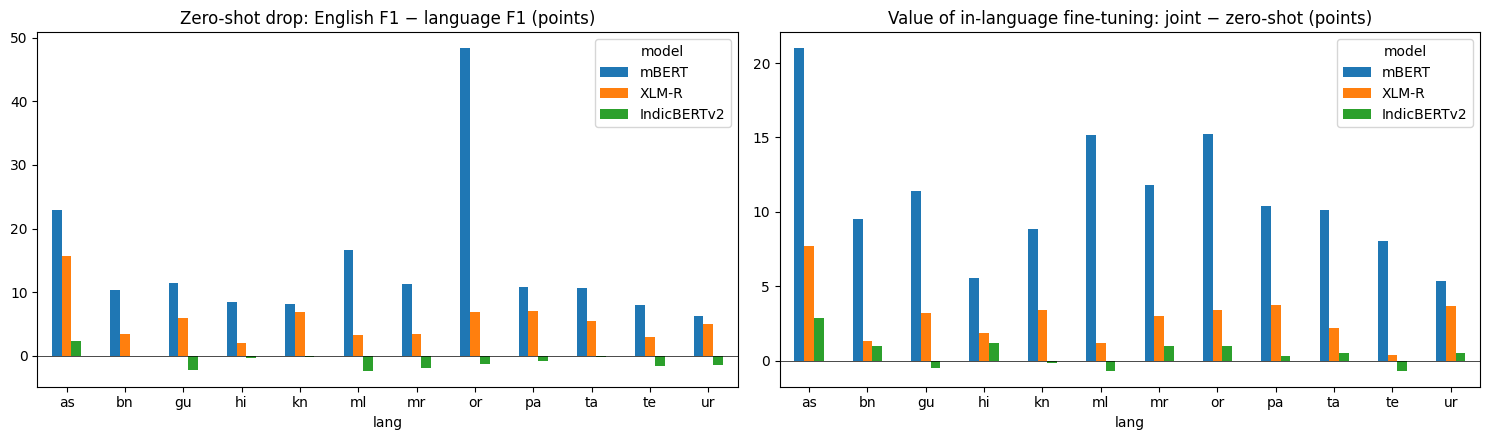

drop_from_English                    joint_minus_zeroshot        \
model             mBERT  XLM-R IndicBERTv2                mBERT XLM-R   
lang                                                                    
as                22.98  15.70        2.36                20.99  7.70   
bn                10.35   3.34       -0.00                 9.50  1.34   
gu                11.42   5.86       -2.17                11.42  3.20   
hi                 8.40   2.00       -0.33                 5.56  1.84   
kn                 8.17   6.89       -0.16                 8.83  3.39   
ml                16.68   3.34       -2.34                15.18  1.17   
mr                11.28   3.35       -2.00                11.78  3.02   
or                48.30   6.88       -1.33                15.20  3.38   
pa                10.76   7.09       -0.83                10.42  3.75   
ta                10.59   5.52       -0.17                10.09  2.17   
te                 8.05   3.02       -1.67                 8.06  0.35   
ur                 6.20   5.04       -1.50                 5.35  3.70   

                   
model IndicBERTv2  
lang               
as           2.87  
bn           1.00  
gu          -0.50  
hi           1.16  
kn          -0.16  
ml          -0.67  
mr           1.00  
or           1.01  
pa           0.33  
ta           0.50  
te          -0.67  
ur           0.50

Mean zero-shot drop (pts): {'mBERT': 14.43, 'XLM-R': 5.67, 'IndicBERTv2': -0.84}


In [ ]:
# ---- Cross-lingual transfer: how much does each model lose when it never saw the language at fine-tuning time? ----
if {"joint", "zeroshot"} <= set(M.setup.unique()):
    pv = M[M.lang != "en"].groupby(["model", "lang", "setup"]).f1_macro.mean().unstack("setup")
    pv["transfer_cost_pts"] = 100 * (pv["joint"] - pv["zeroshot"])      # joint - zero-shot (Macro-F1 points)
    en0 = M[(M.lang == "en") & (M.setup == "zeroshot")].groupby("model").f1_macro.mean()
    pv["drop_from_English_pts"] = [100 * (en0[m] - pv.loc[(m, l), "zeroshot"]) for m, l in pv.index]  # EN -> lang, zero-shot
    tc = pv["transfer_cost_pts"].unstack("model")[list(MODELS)].loc[[l for l in LANGS if l in pv.index.get_level_values(1)]]
    dr = pv["drop_from_English_pts"].unstack("model")[list(MODELS)].loc[tc.index]
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    dr.plot.bar(ax=axes[0], rot=0); axes[0].set_title("Zero-shot drop: English F1 − language F1 (points)"); axes[0].axhline(0, c="k", lw=.5)
    tc.plot.bar(ax=axes[1], rot=0); axes[1].set_title("Value of in-language fine-tuning: joint − zero-shot (points)"); axes[1].axhline(0, c="k", lw=.5)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_transfer.png", dpi=200); plt.show()
    display(pd.concat({"drop_from_English": dr, "joint_minus_zeroshot": tc}, axis=1).round(2))
    print("Mean zero-shot drop (pts):", dr.mean().round(2).to_dict())

### 7.3 Are the differences real? Paired bootstrap over *reviews*
We resample review ids (all languages of a review move together) so the confidence intervals respect the parallel structure of the data.

In [ ]:
def per_review_correct(setup):
    p = preds[(preds.setup == setup) & (preds.lang != "en")].copy()
    p["c"] = (p.y_true == p.y_pred).astype(float)
    return p.pivot_table(index="review_id", columns="model", values="c", aggfunc="mean")   # avg over languages & seeds

rng = np.random.default_rng(0)
boot_rows = []
for s in preds.setup.unique():
    A = per_review_correct(s)
    for a, b in [("XLM-R", "mBERT"), ("IndicBERTv2", "mBERT"), ("IndicBERTv2", "XLM-R")]:
        d = (A[a] - A[b]).values; N = len(d)
        bs = d[rng.integers(0, N, (5000, N))].mean(1)
        lo, hi = np.percentile(bs, [2.5, 97.5])
        boot_rows.append(dict(setup=s, comparison=f"{a} − {b}", mean_diff_acc_pts=100 * d.mean(),
                              ci95_low=100 * lo, ci95_high=100 * hi,
                              verdict="significant" if lo > 0 or hi < 0 else "not significant"))
boot = pd.DataFrame(boot_rows).round(2); display(boot); boot.to_csv(f"{OUT_DIR}/table_bootstrap.csv", index=False)

,setup,comparison,mean_diff_acc_pts,ci95_low,ci95_high,verdict
0,joint,XLM-R − mBERT,11.26,9.10,13.56,significant
1,joint,IndicBERTv2 − mBERT,13.06,10.43,15.90,significant
2,joint,IndicBERTv2 − XLM-R,1.79,0.53,3.19,significant
3,zeroshot,XLM-R − mBERT,18.29,15.57,21.20,significant
4,zeroshot,IndicBERTv2 − mBERT,22.40,19.29,25.62,significant
5,zeroshot,IndicBERTv2 − XLM-R,4.11,2.79,5.54,significant


### 7.4 Tokenization, language coverage and language family vs. performance
Tests the "pretraining corpus / supported languages / tokenization / language-specific characteristics" explanations with numbers instead of assertions.

▶ Spearman correlation between tokenizer fertility and Macro-F1 (across languages)


,setup,model,n_points,spearman_rho,p_value
0,joint,mBERT,12,0.336,0.2861
1,joint,XLM-R,12,-0.671,0.0168
2,joint,IndicBERTv2,12,-0.343,0.2756
3,joint,ALL MODELS,36,-0.640,0.0000
4,zeroshot,mBERT,12,-0.140,0.6646
5,zeroshot,XLM-R,12,-0.238,0.4568
6,zeroshot,IndicBERTv2,12,0.105,0.7456
7,zeroshot,ALL MODELS,36,-0.647,0.0000



▶ Seen vs. unseen in pretraining (Macro-F1 %, mean over languages)


seen_in_pretraining   False  True 
setup    model                    
joint    IndicBERTv2    NaN  96.21
         XLM-R          NaN  94.41
         mBERT        68.95  85.92
zeroshot IndicBERTv2    NaN  95.68
         XLM-R          NaN  91.50
         mBERT        50.85  76.30


▶ mBERT on the two languages absent from its pretraining vs. the rest


group,as/or (unseen),other 10
setup,,
joint,68.95,85.92
zeroshot,50.85,76.30



▶ Language family (Macro-F1 %): Dravidian is agglutinative with long inflected words → higher fertility


f1            fertility           
family               Dravidian Indo-Aryan Dravidian Indo-Aryan
setup    model                                                
joint    IndicBERTv2     95.66      96.48      1.79       1.41
         XLM-R           94.24      94.50      2.47       1.95
         mBERT           86.16      81.56      3.92       2.53
zeroshot IndicBERTv2     95.91      95.56      1.79       1.41
         XLM-R           92.47      91.01      2.47       1.95
         mBERT           75.62      70.28      3.92       2.53

model                      IndicBERTv2  XLM-R  mBERT
setup    script                                     
joint    Bengali-Assamese         95.6   92.2   85.1
         Devanagari               97.1   96.9   85.3
         Gujarati                 96.5   94.5   86.5
         Gurmukhi                 96.0   93.8   86.2
         Kannada                  94.8   93.7   87.2
         Malayalam                96.5   95.0   85.0
         Odia                     97.2   93.7   53.4
         Perso-Arabic             96.8   95.8   85.6
         Tamil                    95.5   93.8   86.0
         Telugu                   95.8   94.5   86.5
zeroshot Bengali-Assamese         93.6   87.6   69.8
         Devanagari               96.0   94.5   76.7
         Gujarati                 97.0   91.3   75.1
         Gurmukhi                 95.7   90.1   75.7
         Kannada                  95.0   90.3   78.3
         Malayalam                97.2   93.8   69.8
         Odia                     96.2   90.3   38.2
         Perso-Arabic             96.3   92.1   80.3
         Tamil                    95.0   91.6   75.9
         Telugu                   96.5   94.1   78.4

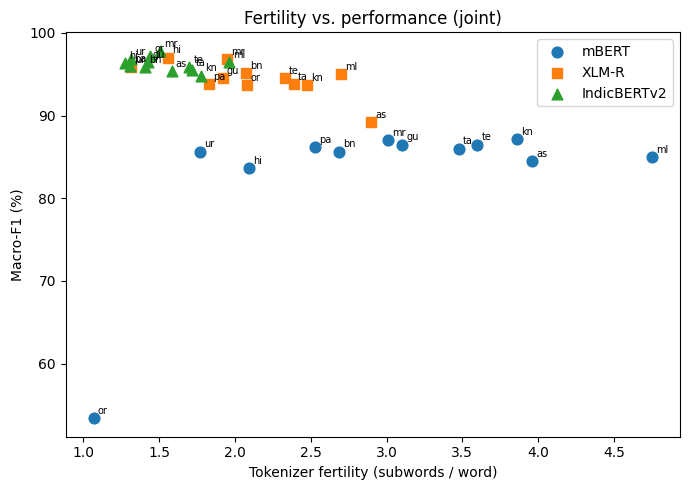

In [ ]:
sc = (M[M.lang != "en"].groupby(["setup", "model", "lang"]).f1_macro.mean().reset_index()
        .merge(fert[["model", "lang", "fertility", "unk_rate"]], on=["model", "lang"]))
sc["seen_in_pretraining"] = [l in COVERAGE[m] for m, l in zip(sc.model, sc.lang)]
sc["family"] = sc.lang.map(lambda l: LANG_INFO[l][2]); sc["script"] = sc.lang.map(lambda l: LANG_INFO[l][1])

print("▶ Spearman correlation between tokenizer fertility and Macro-F1 (across languages)")
rows = []
for s in sc.setup.unique():
    for m in list(MODELS) + ["ALL MODELS"]:
        g = sc[(sc.setup == s) & ((sc.model == m) | (m == "ALL MODELS"))]
        if len(g) > 3 and g.fertility.nunique() > 1:
            r, p = spearmanr(g.fertility, g.f1_macro)
            rows.append(dict(setup=s, model=m, n_points=len(g), spearman_rho=round(r, 3), p_value=round(p, 4)))
display(pd.DataFrame(rows))

print("\n▶ Seen vs. unseen in pretraining (Macro-F1 %, mean over languages)")
display((sc.groupby(["setup", "model", "seen_in_pretraining"]).f1_macro.mean().mul(100).round(2).unstack("seen_in_pretraining")))
if "mBERT" in sc.model.values:
    print("\n▶ mBERT on the two languages absent from its pretraining vs. the rest")
    display(sc[sc.model == "mBERT"].assign(group=lambda d: np.where(d.lang.isin(["as", "or"]), "as/or (unseen)", "other 10"))
              .groupby(["setup", "group"]).f1_macro.mean().mul(100).round(2).unstack("group"))

print("\n▶ Language family (Macro-F1 %): Dravidian is agglutinative with long inflected words → higher fertility")
display(sc.groupby(["setup", "model", "family"]).agg(f1=("f1_macro", lambda x: round(100 * x.mean(), 2)), fertility=("fertility", "mean")).round(2).unstack("family"))
display(sc.groupby(["setup", "model", "script"]).f1_macro.mean().mul(100).round(1).unstack("model").loc[lambda d: d.index.get_level_values(1).notna()])

fig, ax = plt.subplots(figsize=(7, 5))
mk = {"mBERT": "o", "XLM-R": "s", "IndicBERTv2": "^"}
g = sc[sc.setup == sc.setup.unique()[0]]
for m in MODELS:
    gm = g[g.model == m]; ax.scatter(gm.fertility, gm.f1_macro * 100, marker=mk[m], s=60, label=m)
    for _, r in gm.iterrows(): ax.annotate(r.lang, (r.fertility, r.f1_macro * 100), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Tokenizer fertility (subwords / word)"); ax.set_ylabel("Macro-F1 (%)"); ax.set_title(f"Fertility vs. performance ({g.setup.iloc[0]})"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_fertility_vs_f1.png", dpi=200); plt.show()

## 8. Error analysis
All analysis uses one training seed (`ERR_SEED`) so the same predictions are compared across models. Change `ERR_SETUP` to `"zeroshot"` to see transfer-specific errors.

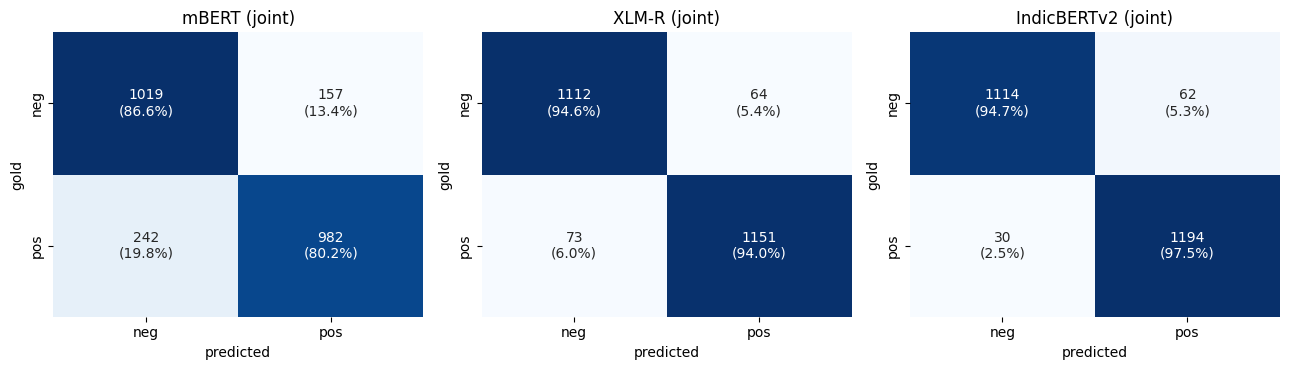


▶ Error rate (%) by review length (terciles of English length)


model,mBERT,XLM-R,IndicBERTv2,n
length_bucket,,,,
short,19.3,9.2,5.8,804
medium,16.0,5.1,2.8,792
long,14.6,2.9,2.9,804



▶ Error rate (%) by English source contains negation


model,mBERT,XLM-R,IndicBERTv2,n
has_negation,,,,
False,17.0,6.0,4.6,1656
True,15.9,5.0,2.0,744



▶ Error rate (%) by English source contains contrast marker (but/however...)


model,mBERT,XLM-R,IndicBERTv2,n
has_contrast,,,,
False,16.5,5.9,4.0,2148
True,17.9,4.4,2.8,252



▶ Error rate (%) by Indic text contains residual Latin words


model,mBERT,XLM-R,IndicBERTv2,n
code_mixed,,,,
False,16.1,5.6,3.9,2267
True,26.3,6.8,3.0,133



▶ Error rate (%) by gold class


model,mBERT,XLM-R,IndicBERTv2
y_true,,,
gold=negative,13.4,5.4,5.3
gold=positive,19.8,6.0,2.5


In [ ]:
ERR_SETUP, ERR_SEED = "joint", SEEDS[0]
if ERR_SETUP not in preds.setup.unique(): ERR_SETUP = preds.setup.unique()[0]

info = df[df.split == "test"][["review_id", "lang", "text", "english", "latin_share"]]
E = preds[(preds.setup == ERR_SETUP) & (preds.seed == ERR_SEED)].merge(info, on=["review_id", "lang"])
E["err"] = (E.y_true != E.y_pred).astype(int)
E["en_words"] = E.english.str.split().str.len()
neg_re = re.compile(r"\b(not|no|never|nothing|nobody|without|neither|nor|hardly|barely)\b|n't")
con_re = re.compile(r"\b(but|however|although|though|yet|except|still)\b")
E["has_negation"] = E.english.str.lower().map(lambda s: bool(neg_re.search(s)))
E["has_contrast"] = E.english.str.lower().map(lambda s: bool(con_re.search(s)))
E["code_mixed"] = E.latin_share.fillna(0) > 0
I = E[E.lang != "en"]

# 8.1 confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, m in zip(axes, MODELS):
    g = I[I.model == m]; cm = confusion_matrix(g.y_true, g.y_pred, labels=[0, 1])
    sns.heatmap(cm / cm.sum(1, keepdims=True) * 100, annot=[[f"{v}\n({100*v/cm[i].sum():.1f}%)" for v in row] for i, row in enumerate(cm)],
                fmt="", cmap="Blues", ax=ax, cbar=False, xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
    ax.set_title(f"{m} ({ERR_SETUP})"); ax.set_xlabel("predicted"); ax.set_ylabel("gold")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_confusion.png", dpi=200); plt.show()

# 8.2 where do errors concentrate? (error rate %, Indian languages pooled)
def err_by(col, labels=None):
    t = I.groupby([col, "model"]).err.mean().mul(100).round(1).unstack("model")[list(MODELS)]
    t["n"] = I[I.model == "mBERT"].groupby(col).size() if "mBERT" in I.model.values else np.nan
    return t
_rl = I.drop_duplicates("review_id").set_index("review_id").en_words              # bucket per REVIEW so every model sees the same buckets
_b = pd.qcut(_rl.rank(method="first"), 3, labels=["short", "medium", "long"])
I = I.assign(length_bucket=I.review_id.map(_b))
for col, nm in [("length_bucket", "review length (terciles of English length)"), ("has_negation", "English source contains negation"),
                ("has_contrast", "English source contains contrast marker (but/however...)"), ("code_mixed", "Indic text contains residual Latin words")]:
    print(f"\n▶ Error rate (%) by {nm}"); display(err_by(col))
print("\n▶ Error rate (%) by gold class"); display(I.groupby(["y_true", "model"]).err.mean().mul(100).round(1).unstack("model")[list(MODELS)].rename(index={0: "gold=negative", 1: "gold=positive"}))

In [ ]:
# 8.3 Parallel-review decomposition: intrinsic difficulty vs. model/language-specific failure
R = I.pivot_table(index=["review_id", "lang"], columns="model", values="err")[list(MODELS)]
rev_err = I.groupby("review_id").err.mean()                       # share of (model x language) cells that are wrong
universal = set(rev_err[rev_err >= 0.75].index)                    # wrong almost everywhere -> ambiguous / noisy label / hard review
print(f"Reviews misclassified in >=75% of all (model x language) cells: {len(universal)} of {I.review_id.nunique()} test reviews")
for m in MODELS:
    g = I[(I.model == m) & (I.err == 1)]
    print(f"  {m:12s}: {100*g.review_id.isin(universal).mean():.1f}% of its errors fall on these 'universally hard' reviews "
          f"(=> intrinsic difficulty), {100*(1-g.review_id.isin(universal).mean()):.1f}% are model/language-specific")

uniq = {m: R[(R[m] == 1) & (R.drop(columns=m).sum(axis=1) == 0)] for m in MODELS}        # only this model is wrong
print("\n▶ Errors made ONLY by one model (others correct) — per language")
display(pd.DataFrame({m: u.reset_index().groupby("lang").size() for m, u in uniq.items()}).reindex(LANGS).fillna(0).astype(int))

# 8.4 qualitative examples (read these and write your analysis!)
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 250)
print("\n▶ Universally hard reviews (English source shown; gold label in last column)")
uh = (E[(E.review_id.isin(universal)) & (E.lang == "en")].drop_duplicates("review_id")[["review_id", "english", "y_true"]]
      .assign(gold=lambda d: d.y_true.map({0: "negative", 1: "positive"})).head(8))
display(uh[["review_id", "english", "gold"]])

def show_examples(m, n=5, seed=1):
    u = uniq[m].reset_index()
    if u.empty: print(f"{m}: no unique errors"); return
    u = u.sample(min(n, len(u)), random_state=seed).merge(I[I.model == m][["review_id", "lang", "text", "english", "y_true", "y_pred", "p_pos"]], on=["review_id", "lang"])
    u["gold→pred"] = u.y_true.map({0: "neg", 1: "pos"}) + "→" + u.y_pred.map({0: "neg", 1: "pos"})
    u["text"] = u.text.str.slice(0, 130); u["english"] = u.english.str.slice(0, 130)
    print(f"\n▶ {m}: errors where the other two models are right"); display(u[["lang", "gold→pred", "p_pos", "text", "english"]].round(3))
for m in MODELS: show_examples(m)

Reviews misclassified in >=75% of all (model x language) cells: 0 of 200 test reviews
  mBERT       : 0.0% of its errors fall on these 'universally hard' reviews (=> intrinsic difficulty), 100.0% are model/language-specific
  XLM-R       : 0.0% of its errors fall on these 'universally hard' reviews (=> intrinsic difficulty), 100.0% are model/language-specific
  IndicBERTv2 : 0.0% of its errors fall on these 'universally hard' reviews (=> intrinsic difficulty), 100.0% are model/language-specific

▶ Errors made ONLY by one model (others correct) — per language


,mBERT,XLM-R,IndicBERTv2
lang,,,
as,14,11,1
bn,23,0,4
gu,18,2,1
hi,25,0,4
kn,16,5,4
ml,17,2,3
mr,23,2,1
or,86,3,1
pa,12,1,2



▶ Universally hard reviews (English source shown; gold label in last column)


,review_id,english,gold



▶ mBERT: errors where the other two models are right


,lang,gold→pred,p_pos,text,english
0,ml,pos→neg,0.004,രോമം മുറിക്കുമ്പോൾ അതിന്റെ കുറഞ്ഞ വിറയൽ വളർത്തുമൃഗങ്ങളുടെ ആശങ്ക കുറയ്ക്കുന്നു.,Its low viberation reduces the pet anxiety when doing hair trimming.
1,or,pos→neg,0.388,ବହୁତ ଭଲ ରକ୍ଷଣାବେକ୍ଷଣ ହୋଇଥିବା ଷ୍ଟେସନ୍ ଏବଂ କୋଚ୍,Very well maintained stations and coaches
2,kn,neg→pos,0.998,"ಅವರು ಹೊಟ್ಟೆಯ ತೊಂದರೆಗಳು, ಸಡಿಲವಾದ ಚಲನೆಗಳು ಮತ್ತು ವಾಂತಿಗಳಿಂದ ಬಳಲುತ್ತಿದ್ದಾರೆ","They suffer from stomach problems, losse motions and vomiting"
3,or,pos→neg,0.457,ତୀକ୍ଷ୍ଣ ଫ୍ଲାସ୍ ଲାଇଟ୍ ଠାରୁ ସମୟ ସମୟରେ ଶଟ୍ ପରିଚାଳନା କରିବାକୁ ଏକ ଅର୍ଥ ପ୍ରଦାନ କରେ ଏବଂ ଭେଲକ୍ରୋଭ୍ ମାଉଣ୍ଟ୍ କରିବା ଠିକ୍ |,Gives a sense to manage shots time to time from sharp flash lights and the velcrove is quite right to mount.
4,kn,pos→neg,0.478,ಇದು ಕಲ್ಲಿನ ನಿರ್ಮಾಣಗಳು ಅಥವಾ ಪ್ಲ್ಯಾಸ್ಟರಿಂಗ್ ಕೆಲಸಗಳಲ್ಲಿ ಗಾರೆ ಕೆಲಸ ಮಾಡಲು ದೊಡ್ಡ ಸಮಯದ ವಿಂಡೋವನ್ನು ಒದಗಿಸುವ ಸಮಯವನ್ನು ಹೊಂದಿಸುತ್ತದೆ.,It has longer setting time providing large time window to work the mortar in masonry constructions or plastering work.



▶ XLM-R: errors where the other two models are right


,lang,gold→pred,p_pos,text,english
0,as,neg→pos,0.998,এইখন মই বহু বছৰ মূৰত দেখা আটাইতকৈ বেয়া চিনেমা!!! জঘন্য অভিনয় আৰু ধৰ্মীয় প্ৰৱঞ্চনাৰে পৰিপূৰ্ণ এক অস্তিত্বহীন কাহিনী!,This the worst movie I have seen in years!!! Horrible acting and a nonexistent story full of religious dribble!
1,kn,pos→neg,0.001,ಪ್ಲೇಕ್ ಮತ್ತು ಟಾರ್ಟಾರ್ನ ಹಲ್ಲುಗಳನ್ನು ಅಗೋಚರವಾಗಿ ಸ್ವಚ್ಛಗೊಳಿಸಲು ಮತ್ತು ಉಸಿರಾಟವನ್ನು ಫ್ರೆಶ್ ಮಾಡಲು ಕೆಲಸ ಮಾಡುತ್ತದೆ.,Works to invisibly clean teeth of plaque and tartar and freshens breath.
2,as,neg→pos,0.996,গোন্ধটো আন ৰূম ফ্ৰেছনাৰৰ দৰে কেৱল কেইমিনিটমানৰ বাবে থাকে।,The smell stays only for couple of minutes just like any other room freshner.
3,or,neg→pos,0.999,କ୍ରୋମା ଏପର୍ଯ୍ୟନ୍ତ ପାରମ୍ପରିକ ଆଲୁମିନିୟମ୍ କଏଲ୍ ସହିତ ଏସି ଉତ୍ପାଦନ କରୁଛି | ଏଗୁଡ଼ିକ କ୍ଷୟ ପାଇଁ ଅଧିକ ପ୍ରବୃତ୍ତ ଏବଂ କମ୍ ଶକ୍ତି ଦକ୍ଷ |,Croma is still producing ACs with traditional Alluminium coils. These are more prone to corrosion and less energy efficient.
4,kn,neg→pos,0.912,ತೊಳೆಯುವ ನಂತರ ವಿರೂಪಗೊಳ್ಳುತ್ತದೆ.,It gets deformed after washing.



▶ IndicBERTv2: errors where the other two models are right


,lang,gold→pred,p_pos,text,english
0,te,neg→pos,0.950,"""మీరు క్యాన్సిల్ చేసినప్పుడు, వివిధ ఛార్జీలు మినహాయించబడతాయి కనుక మీకు డబ్బులు ఏమాత్రం రావు.""","When you cancel, you get a zero as various charges are deducted."
1,kn,neg→pos,0.990,ಯಂತ್ರ ಬೆಚ್ಚಗಾಗುತ್ತದೆ.,The machine heats up.
2,ta,neg→pos,0.602,மற்ற எந்தவொரு ரூம் ஃப்ரெஷ்னரைப் போலவே வாசனை இரண்டு நிமிடங்கள் மட்டுமே இருக்கிறது.,The smell stays only for couple of minutes just like any other room freshner.
3,te,neg→pos,0.838,"మహిళలకు ఈ రోల్ ఆన్ 48 గంటలు పనిచేస్తుందని పేర్కొంది. అయితే, నా అనుభవంలో ఇది 5 గంటలకు మించి ఉండదు.","This roll on for women claims to work for 48 hours. However, in my experience it DOESNT LAST FOR MORE THAN 5 HOURS."
4,pa,neg→pos,0.969,ਬਿਸਕੁਟਾਂ ਦਾ ਨਰਮ ਸੁਆਦ ਉਹਨਾਂ ਨੂੰ ਘੱਟ ਤਰਜੀਹੀ ਵਿਕਲਪ ਬਣਾਉਂਦਾ ਹੈ,The bland taste of the biscuits make them a less preferable option


## 9. Evidence summary for the conclusions (auto-generated from your own results)

In [ ]:
def best(setup):
    t = ps_indic[ps_indic.setup == setup].groupby("model").f1_macro.mean().sort_values(ascending=False)
    return t
lines = []
for s in preds.setup.unique():
    b = best(s); lines.append(f"[{s}] Macro-F1 ranking (12-language mean): " + " > ".join(f"{m} {100*v:.1f}" for m, v in b.items()))
for _, r in boot.iterrows():
    lines.append(f"[{r.setup}] {r.comparison}: {r.mean_diff_acc_pts:+.2f} acc-pts, 95% CI [{r.ci95_low:+.2f}, {r.ci95_high:+.2f}] -> {r.verdict}")
if "mBERT" in sc.model.values:
    for s in sc.setup.unique():
        g = sc[(sc.setup == s) & (sc.model == "mBERT")]
        u, v = g[g.lang.isin(["as", "or"])].f1_macro.mean(), g[~g.lang.isin(["as", "or"])].f1_macro.mean()
        lines.append(f"[{s}] mBERT Macro-F1 on unseen as/or = {100*u:.1f} vs {100*v:.1f} on the other languages (gap {100*(v-u):+.1f})")
for s in sc.setup.unique():
    for m in MODELS:
        g = sc[(sc.setup == s) & (sc.model == m)]
        if len(g) > 3 and g.fertility.nunique() > 1:
            r, p = spearmanr(g.fertility, g.f1_macro); lines.append(f"[{s}] {m}: fertility vs Macro-F1 Spearman rho = {r:+.2f} (p={p:.3f})")
print("\n".join("• " + l for l in lines))

• [joint] Macro-F1 ranking (12-language mean): IndicBERTv2 96.2 > XLM-R 94.4 > mBERT 83.1
• [zeroshot] Macro-F1 ranking (12-language mean): IndicBERTv2 95.7 > XLM-R 91.5 > mBERT 72.1
• [joint] XLM-R − mBERT: +11.26 acc-pts, 95% CI [+9.10, +13.56] -> significant
• [joint] IndicBERTv2 − mBERT: +13.06 acc-pts, 95% CI [+10.43, +15.90] -> significant
• [joint] IndicBERTv2 − XLM-R: +1.79 acc-pts, 95% CI [+0.53, +3.19] -> significant
• [zeroshot] XLM-R − mBERT: +18.29 acc-pts, 95% CI [+15.57, +21.20] -> significant
• [zeroshot] IndicBERTv2 − mBERT: +22.40 acc-pts, 95% CI [+19.29, +25.62] -> significant
• [zeroshot] IndicBERTv2 − XLM-R: +4.11 acc-pts, 95% CI [+2.79, +5.54] -> significant
• [joint] mBERT Macro-F1 on unseen as/or = 68.9 vs 85.9 on the other languages (gap +17.0)
• [zeroshot] mBERT Macro-F1 on unseen as/or = 50.9 vs 76.3 on the other languages (gap +25.5)
• [joint] mBERT: fertility vs Macro-F1 Spearman rho = +0.34 (p=0.286)
• [joint] XLM-R: fertility vs Macro-F1 Spearman rho = -0

## 10. Report-writing guide (how to turn the outputs above into the 10 required points)

**Use the tables you generated — never write "model X is better" without a number or a CI behind it.**

### Model background to cite (verify figures against the original papers/model cards)
| | mBERT | XLM-RoBERTa-base | IndicBERT v2 (MLM-only) |
|---|---|---|---|
| Pretraining corpus | Wikipedia | CC-100 (CommonCrawl), far larger and noisier web text | IndicCorp v2, a large web corpus focused on Indian languages |
| Languages | 104 (no Assamese, no Odia) | 100 (includes Assamese, Odia, but with little data) | 23 Indian languages + English |
| Vocabulary | ~119k WordPiece, shared by 104 languages | 250k SentencePiece | 250k vocabulary built for Indic scripts |
| Objective / architecture | BERT: MLM + NSP, 12 layers | RoBERTa-style: MLM only, dynamic masking, 12 layers | BERT-style MLM, 12 layers |
| Approx. parameters | ~178M | ~278M | ~278M |

### How to argue each factor (Requirement 7) — one paragraph each, citing your numbers
1. **Pretraining corpus** – link Wikipedia size vs. web-scale data to the *seen/unseen* table (7.4) and the language-wise heat-map (7.2). Low-resource Wikipedias (e.g. Assamese, Odia) → weak mBERT representations.
2. **Number/diversity of languages** – "curse of multilinguality": 104 languages share mBERT's capacity; IndicBERT v2 concentrates capacity on Indian languages. Support with the joint-vs-zero-shot comparison.
3. **Tokenization / vocabulary** – quote the fertility, UNK and truncation tables (Section 4) and the Spearman table (7.4). If fertility is high for a language, words are shattered into many pieces and sentiment-bearing morphemes are lost. State honestly if correlation is weak.
4. **Cross-lingual transfer** – use the *zero-shot drop* and *transfer cost* plots (7.2). Models with better aligned multilingual spaces lose fewer points when trained only on English.
5. **Architecture** – the three models are all ~12-layer encoders, so differences are mostly data/vocabulary, not architecture. Say this explicitly; do not over-credit "RoBERTa-style training" unless your numbers on languages seen by both models support it.
6. **Dataset characteristics** – small (≈1,000 reviews per language), e-commerce domain, binary labels, human-translated, label noise/ambiguity → see the "universally hard reviews" analysis (8.3). Mention that confidence intervals are wide at n≈200 test reviews.
7. **Language-specific characteristics** – script, family (Dravidian agglutination vs. Indo-Aryan), residual Latin words (code-mixing), Urdu's right-to-left Perso-Arabic script, Assamese–Bengali script sharing (a transfer path for mBERT from Bengali to Assamese).

### Error analysis (Requirement 8) — what to write
* Confusion matrices: does a model over-predict positive or negative? (8.1)
* Error rates by negation / contrast / length / code-mixing (8.2) — name the factor that moves the error rate most.
* Share of errors that are *intrinsic* (universally hard reviews) vs *model/language-specific* (8.3).
* Quote 3–5 concrete misclassified examples from 8.4 (English + Indic text + gold + prediction + a one-line reason).

### Conclusions (Requirements 9–10) — template
> *In joint fine-tuning, A outperformed B by __ points (95% CI [__, __]), [significant / not significant]. The gap was concentrated in languages __ (see Fig. X), which coincide with [languages absent from B's pretraining / languages with highest fertility under B's tokenizer (ρ = __)]. In zero-shot transfer, A lost __ points from English whereas B lost __, indicating __. Errors were dominated by __ (e.g. negation), and __% of all errors fall on reviews that every model misclassifies, so the remaining headroom is partly label ambiguity rather than model weakness.*

Also discuss **limitations**: ~1,000 reviews per language, single domain, only base-size models, 3 seeds, machine-translated English source for some languages is *not* an issue here (translations are human) but the reviews are translations, not natively written text.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
